=== [XGBoost1] 불량 판정 상위 15개 센서 ===


,Sensor,Importance
0,Sensor_459,0.011782
1,Sensor_111,0.011043
2,Sensor_556,0.010538
3,Sensor_103,0.010380
4,Sensor_65,0.010062
5,Sensor_202,0.009652
6,Sensor_319,0.009569
7,Sensor_297,0.009381
8,Sensor_152,0.009379
9,Sensor_59,0.008972



=== [LightGBM1] 불량 판정 상위 15개 센서 ===


,Sensor,Importance
0,Sensor_103,32
1,Sensor_33,25
2,Sensor_477,20
3,Sensor_59,16
4,Sensor_31,15
5,Sensor_213,14
6,Sensor_131,14
7,Sensor_247,14
8,Sensor_130,11
9,Sensor_81,11


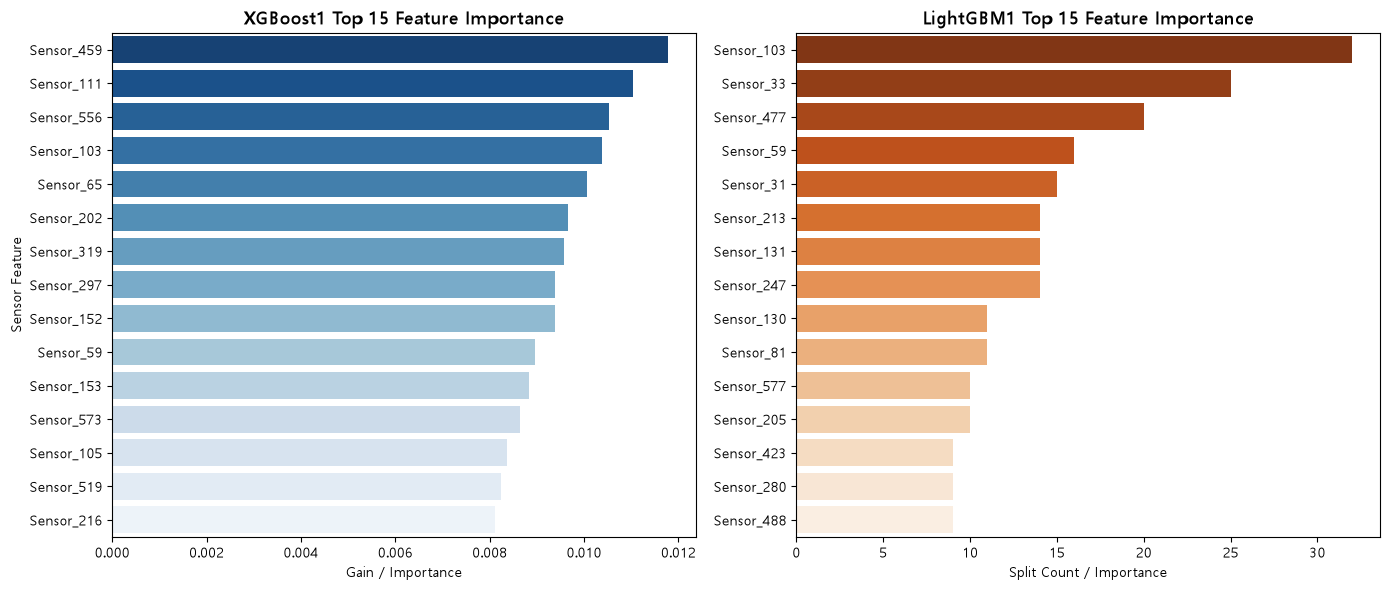


=== 두 모델 상위 15개 중 공통으로 지목된 핵심 센서 (교집합) ===
총 2개: ['Sensor_103', 'Sensor_59']


In [1]:
from pathlib import Path
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

# === Windows 한글 폰트 설정 ===
plt.rc('font', family='Malgun Gothic')
plt.rc('axes', unicode_minus=False)

# 1. 데이터 로드 및 전처리
# 현재 폴더부터 상위로 올라가며 data 폴더 탐색
data_dir = next(p / 'data' for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'secom.data').exists())

df_features = pd.read_csv(data_dir / 'secom.data', sep=r'\s+', header=None)
df_labels = pd.read_csv(
    data_dir / 'secom_labels.data',
    sep=r'\s+',
    header=None,
    usecols=[0],
    names=['Target'],
)

# 컬럼명 부여: Sensor_0 ~ Sensor_589
feature_names = [f'Sensor_{i}' for i in range(df_features.shape[1])]
df_features.columns = feature_names

# Target 레이블 변환 (-1 -> 0: PASS, 1 -> 1: FAIL)
y = (df_labels['Target'] == 1).astype(int).values
X = df_features

# Train / Test 분할 (누수 방지 및 기존 노트북과 동일한 파라미터 적용)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 결측치 대체 (Train 기준 중앙값)
imputer = SimpleImputer(strategy='median')
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train), columns=feature_names
)

# 불균형 가중치 계산
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

# 2. XGBoost1 (튜닝형) 모델 학습 및 피처 중요도 추출
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.05,
    scale_pos_weight=scale_weight,
    subsample=0.8,
    colsample_bytree=0.5,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1,
)
xgb_model.fit(X_train_imputed, y_train)

xgb_importance = pd.DataFrame({
    'Sensor': feature_names,
    'Importance': xgb_model.feature_importances_,
}).sort_values(by='Importance', ascending=False)

# 3. LightGBM1 (튜닝형) 모델 학습 및 피처 중요도 추출
lgb_model = lgb.LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    num_leaves=15,
    max_depth=4,
    scale_pos_weight=scale_weight,
    subsample=0.8,
    colsample_bytree=0.5,
    random_state=42,
    verbosity=-1,
    n_jobs=-1,
)
lgb_model.fit(X_train_imputed, y_train)

lgb_importance = pd.DataFrame({
    'Sensor': feature_names,
    'Importance': lgb_model.feature_importances_,
}).sort_values(by='Importance', ascending=False)

# 4. 상위 15개 센서 데이터프레임 확인
top_n = 15
top_xgb = xgb_importance.head(top_n).reset_index(drop=True)
top_lgb = lgb_importance.head(top_n).reset_index(drop=True)

print(f'=== [XGBoost1] 불량 판정 상위 {top_n}개 센서 ===')
display(top_xgb)

print(f'\n=== [LightGBM1] 불량 판정 상위 {top_n}개 센서 ===')
display(top_lgb)

# 5. 두 모델의 상위 15개 중요 센서 시각화 (좌우 비교)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.barplot(
    data=top_xgb,
    x='Importance',
    y='Sensor',
    ax=axes[0],
    palette='Blues_r',
    hue='Sensor',
    legend=False,
)
axes[0].set_title(
    f'XGBoost1 Top {top_n} Feature Importance',
    fontsize=13,
    fontweight='bold',
)
axes[0].set_xlabel('Gain / Importance')
axes[0].set_ylabel('Sensor Feature')

sns.barplot(
    data=top_lgb,
    x='Importance',
    y='Sensor',
    ax=axes[1],
    palette='Oranges_r',
    hue='Sensor',
    legend=False,
)
axes[1].set_title(
    f'LightGBM1 Top {top_n} Feature Importance',
    fontsize=13,
    fontweight='bold',
)
axes[1].set_xlabel('Split Count / Importance')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

# 6. 두 모델 모두에서 공통으로 중요하게 지목된 센서(교집합) 확인
common_sensors = set(top_xgb['Sensor']).intersection(set(top_lgb['Sensor']))
print(
    f'\n=== 두 모델 상위 {top_n}개 중 공통으로 지목된 핵심 센서 (교집합) ==='
)
print(f'총 {len(common_sensors)}개: {sorted(list(common_sensors))}')